In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from alpha.analysist import datastore
from datetime import datetime, timedelta
import math

In [3]:
local = datastore.DataStore(live=False)

In [27]:
day, next_day="2026-10-23", "2026-10-24"
symbols = local.sql("SELECT DISTINCT symbol FROM tick WHERE dt>=? AND dt<? ORDER BY symbol", [day, next_day])

In [28]:
symbols_lst = [item for tup in symbols[0] for item in tup]

In [29]:
symbols_lst

['000270',
 '000660',
 '003550',
 '005380',
 '005490',
 '005930',
 '006400',
 '012330',
 '034730',
 '035420',
 '035720',
 '051910',
 '055550',
 '066570',
 '068270',
 '086790',
 '105560',
 '316140']

In [30]:
s = symbols_lst[5]
st = " 09:00:00"
et = " 15:30:00"

In [59]:
ticks = local.ticks(symbol=s, start=day+st, end=day+et)

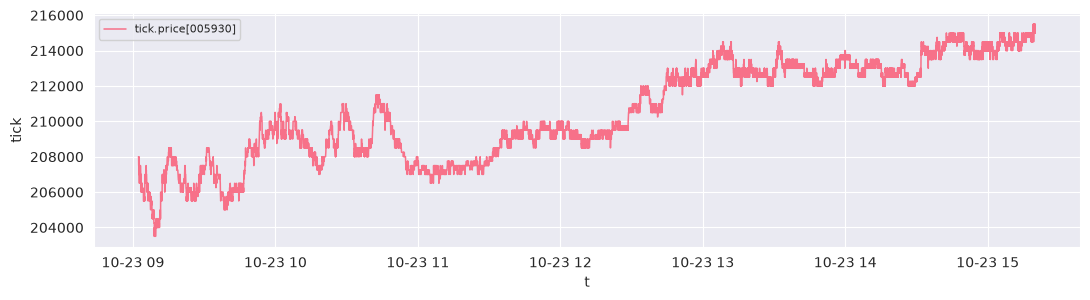

(<Figure size 1100x310 with 1 Axes>, [<Axes: xlabel='t', ylabel='tick'>])

In [60]:
ticks.resample_frame("s").time_frame(mode="s", start=day+st, end=day+et).split_by_gap("1s").segments[0].plot(columns=["price"])

In [113]:
price = ticks.resample_frame("s").time_frame(mode="s", start=day+st, end=day+et).calc('mid', 'bid', '+', 'ask').calc('mid', 'mid', '/', 2)

In [156]:
def scan_level(price, level):
    times = list(price.base.times)
    n = len(price.base.times)
    hits = []
    i = 0
    while i < n:
        t = times[i]
        t5 = t + timedelta(minutes=5)
        pss = price.tslice(t.strftime('%Y-%m-%d %H:%M:%S'), t5.strftime('%Y-%m-%d %H:%M:%S')) \
                   .relative('mid', replace=True).return_passage(y="relative", levels=[level])
        if pss.empty:
            i += 1
            continue
        touch = pss.iloc[:, 0].values[0]        # levels를 하나만 줬으니 늘 t{level} 컬럼
        if touch is not None and not math.isnan(touch):
            hits.append(t)
            next_t = t + timedelta(seconds=int(touch) + 1)   # 이 사건이 끝난 뒤부터 재탐색
        else:
            next_t = t + timedelta(seconds=1)
        while i < n and times[i] < next_t:
            i += 1
    return hits

low = scan_level(price, 0.99)
high = scan_level(price, 1.01)

Task was destroyed but it is pending!
task: <Task pending name='Task-753' coro=<_async_in_context.<locals>.run_in_context() done, defined at /usr/local/lib/python3.12/site-packages/ipykernel/utils.py:57> wait_for=<Task pending name='Task-754' coro=<Kernel.shell_main() running at /usr/local/lib/python3.12/site-packages/ipykernel/kernelbase.py:597> cb=[Task.task_wakeup()]> cb=[ZMQStream._run_callback.<locals>._log_error() at /usr/local/lib/python3.12/site-packages/zmq/eventloop/zmqstream.py:564]>
/usr/local/lib/python3.12/site-packages/pandas/core/arrays/datetimes.py:668: RuntimeWarning: coroutine 'Kernel.shell_main' was never awaited
  converted = ints_to_pydatetime(
Task was destroyed but it is pending!
task: <Task pending name='Task-754' coro=<Kernel.shell_main() running at /usr/local/lib/python3.12/site-packages/ipykernel/kernelbase.py:597> cb=[Task.task_wakeup()]>


In [157]:
print(high)
print(low)

[Timestamp('2026-10-23 09:08:01'), Timestamp('2026-10-23 09:09:53'), Timestamp('2026-10-23 09:10:44'), Timestamp('2026-10-23 09:11:21'), Timestamp('2026-10-23 09:11:57'), Timestamp('2026-10-23 09:13:21'), Timestamp('2026-10-23 09:26:02'), Timestamp('2026-10-23 09:43:48'), Timestamp('2026-10-23 09:46:29'), Timestamp('2026-10-23 09:50:46'), Timestamp('2026-10-23 10:18:04'), Timestamp('2026-10-23 10:19:29'), Timestamp('2026-10-23 10:24:58'), Timestamp('2026-10-23 10:36:25'), Timestamp('2026-10-23 10:38:01'), Timestamp('2026-10-23 10:39:06'), Timestamp('2026-10-23 10:39:48'), Timestamp('2026-10-23 10:40:39'), Timestamp('2026-10-23 12:40:07'), Timestamp('2026-10-23 12:41:25'), Timestamp('2026-10-23 12:42:20')]
[Timestamp('2026-10-23 09:00:00'), Timestamp('2026-10-23 09:01:34'), Timestamp('2026-10-23 09:03:08'), Timestamp('2026-10-23 09:05:14'), Timestamp('2026-10-23 09:15:03'), Timestamp('2026-10-23 09:31:56'), Timestamp('2026-10-23 09:33:36'), Timestamp('2026-10-23 10:28:12'), Timestamp('2

In [203]:
kf = local.indicators(symbol=s, label="OFI_KF", start=day+st, end=day+et)

In [260]:
series = kf.resample_frame("s").time_frame(mode="s", start=day+st, end=day+et).add(price.relative('mid', replace=True)).series()
layout = [([series[4]], [series[-1]]), ([series[5]], [series[1]]),([series[9]], [])]

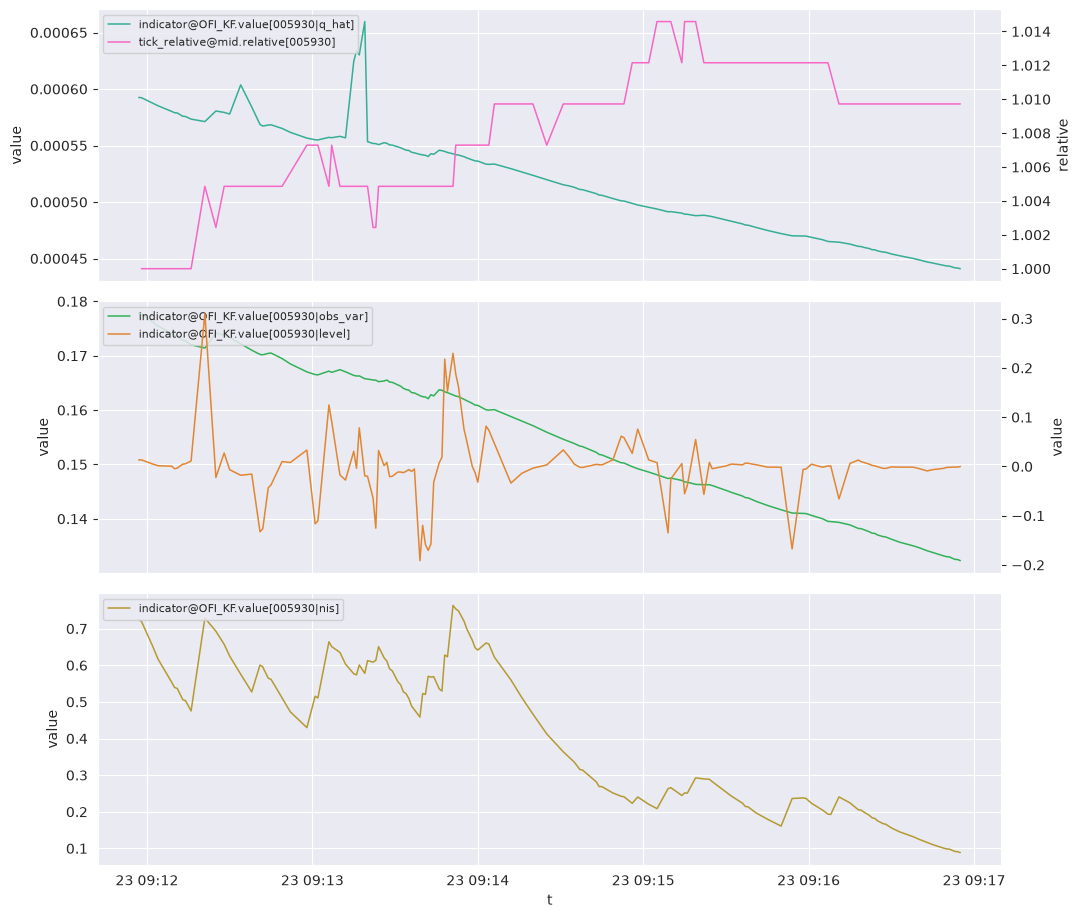

(<Figure size 1100x930 with 5 Axes>,
 [<Axes: ylabel='value'>,
  <Axes: ylabel='value'>,
  <Axes: xlabel='t', ylabel='value'>])

In [267]:
t = high[4]
t5 = t + timedelta(minutes=5)
p = price.resample_frame("s").tslice(t.strftime('%Y-%m-%d %H:%M:%S'), t5.strftime('%Y-%m-%d %H:%M:%S')).relative('mid', replace=True)
kf.tslice(t.strftime('%Y-%m-%d %H:%M:%S'), t5.strftime('%Y-%m-%d %H:%M:%S')).add(p).plot(layout=layout)

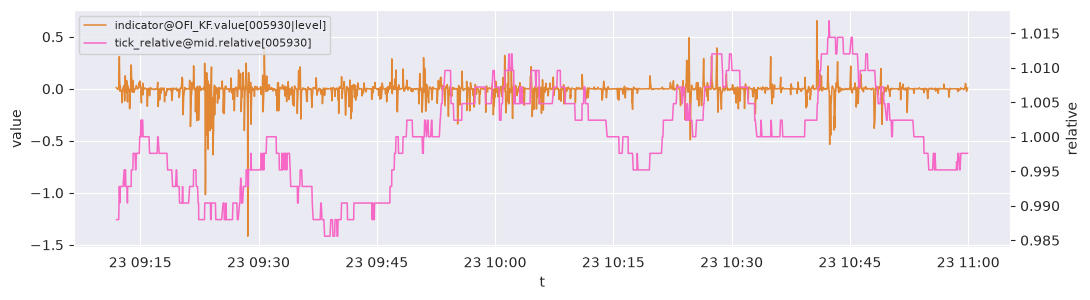

(<Figure size 1100x310 with 2 Axes>, [<Axes: xlabel='t', ylabel='value'>])

In [268]:
kf.tslice(t.strftime('%Y-%m-%d %H:%M:%S'), day+' 11:00:00').add(price.resample_frame("s").relative('mid', replace=True)).plot(layout=[(['indicator@OFI_KF.value[005930|level]'], ['tick_relative@mid.relative[005930]'])])

In [31]:
flow = local.indicators(symbol=s, label="BestQuoteFlow", start=day+st, end=day+et)
kf = local.indicators(symbol=s, label="OFI_KF", start=day+st, end=day+et)

In [35]:
s = flow.resample_frame("s").add(kf).tslice(day+' 09:00:00', day+' 11:00:00').series()
s

['indicator@BestQuoteFlow.value[005930|ask_flow]',
 'indicator@BestQuoteFlow.value[005930|bid_flow]',
 'indicator@BestQuoteFlow.value[005930|ofi]',
 'indicator@BestQuoteFlow.value[005930|dup_frac]',
 'indicator@BestQuoteFlow.value[005930|ofi_norm]',
 'indicator@BestQuoteFlow.value[005930|truncated]',
 'indicator@BestQuoteFlow.value[005930|is_dup]',
 'indicator@OFI_KF.value[005930|lead]',
 'indicator@OFI_KF.value[005930|world_frac]',
 'indicator@OFI_KF.value[005930|surprise]',
 'indicator@OFI_KF.value[005930|slope]',
 'indicator@OFI_KF.value[005930|r_surprise]',
 'indicator@OFI_KF.value[005930|q_hat]',
 'indicator@OFI_KF.value[005930|obs_var]',
 'indicator@OFI_KF.value[005930|nis_raw]',
 'indicator@OFI_KF.value[005930|nis]',
 'indicator@OFI_KF.value[005930|level]']

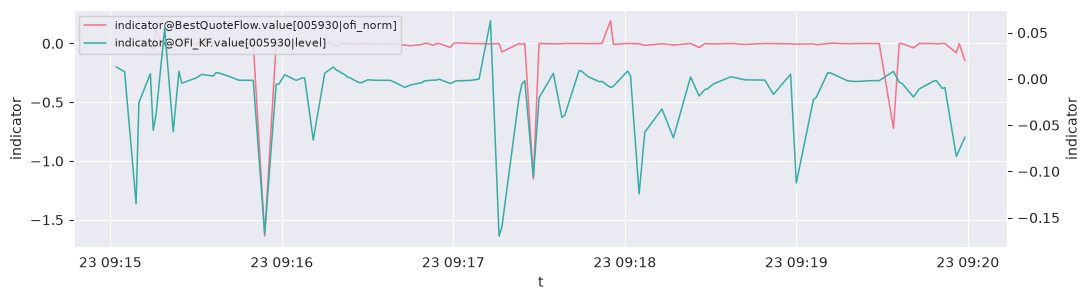

(<Figure size 1100x310 with 2 Axes>, [<Axes: xlabel='t', ylabel='indicator'>])

In [43]:
flow.resample_frame("s").add(kf).tslice(day+' 09:15:00', day+' 09:20:00').plot(columns=[s[4], s[-1]])